In [292]:
import tskit
import pandas as pd
import numpy as np
from collections import Counter
from matplotlib import pyplot as plt
import scipy
import seaborn as sns
from matplotlib.patches import Patch

chromosome = 16

In [10]:
originalTs = tskit.load("All_snps_with_outgroup_info_newAA/Chr" + str(chromosome) + ".trees")
remappedTs = tskit.load("Remapped_newNe/Chr" + str(chromosome) + ".trees")
chrSample = pd.read_table("All_snps_with_outgroup_info_newAA/Chr" + str(chromosome) + "_relate.sample")


# %%
meta = pd.read_csv("TsinferMetaData_Vcf.txt")
meta.head()
allMeta = pd.read_csv("/home/jobste/Data/DataDescriptor_SampleMeta.csv")
allMeta.head()
meta.loc[:, "Country"] = [allMeta.Country[allMeta.Run == x].to_list()[0] for x in meta.ID]

In [37]:
# Add country as pop

sampleMeta = chrSample.merge(meta, how = "left", left_on = "ID_1", right_on = "ID")
sampleMeta = sampleMeta.iloc[1: , :]


complex_schema_pop = tskit.MetadataSchema({
    'codec': 'json',
    'additionalProperties': False,
    'properties': {'pop': {'description': 'Lineage',
                           'type': 'string'},
                   'subpop': {'description': 'Subspecies',
                           'type': 'string'},
                   'country': {'description': 'Country',
                           'type': 'string'}},
    'required': ['pop'],
    'type': 'object',
})

remappedTables = remappedTs.dump_tables()
remappedTables.populations.metadata_schema = complex_schema_pop

# Add data to population table
popdata_column = [{"pop": pop, "subpop":subpop, "country": country } for pop,subpop,country in set(list(zip(meta.Pop, meta.SubPop, meta.Country)))]
encoded_popdata_column = [
    remappedTables.populations.metadata_schema.validate_and_encode_row(r) for r in popdata_column
]
md, md_offset = tskit.pack_bytes(encoded_popdata_column)
remappedTables.populations.set_columns(metadata=md, metadata_offset=md_offset)

popDict = {y: x for x,y in enumerate(set(list(zip(meta.Pop, meta.SubPop, meta.Country))))}
ind_nodes = list([x.id for x in remappedTs.individuals()])
ind_pops = [popDict[(sampleMeta.Pop.to_list()[x], sampleMeta.SubPop.to_list()[x], sampleMeta.Country.to_list()[x])] for x in ind_nodes]

In [38]:
indNodePopR = remappedTables.nodes.population
indNodePopR[ind_nodes] = ind_pops
remappedTables.nodes.population = indNodePopR
remappedTs_meta = remappedTables.tree_sequence()

In [61]:
remappedTs_meta.node(0)

Node(id=0, flags=1, time=0.0, population=3, individual=-1, metadata=b'\x00\x00\x00\x00\x00\x00\x00\x00')

In [39]:
ind_by_ind = [[x] for x in ind_nodes]
indexes = [(x, y) for x in ind_nodes for y in ind_nodes]

In [22]:
Z = remappedTs_meta.genetic_relatedness(ind_by_ind, indexes = indexes)

In [43]:
nonHPop = [x.id for x in remappedTs_meta.populations() if x.metadata["pop"] in ["A", "C", "O", "M"]]

In [44]:
from itertools import chain
nonH = list(chain.from_iterable([remappedTs_meta.samples(pop) for pop in nonHPop]))

In [ ]:
#remappedTs_nonH = remappedTs_meta.simplify(nonH) # This doesn't work

In [139]:
remappedTs_meta.num_samples

1328

In [157]:
lineages = set([x.metadata["pop"] for x in remappedTs_meta.populations()])
nonH_lineages = ["A", "C", "M", "O"]
subspecies = set([x.metadata["subpop"] for x in remappedTs_meta.populations()])
countries = set([x.metadata["country"] for x in remappedTs_meta.populations()])

nonH_nodes = [remappedTs_meta.node(n) for n in remappedTs_meta.samples() if remappedTs_meta.population(remappedTs_meta.node(n).population).metadata["pop"] in nonH_lineages]
nonH_nodes_by_ind = [[x] for x in nonH_nodes]

In [163]:
#GNN
samples_listed_by_subsp_nonH = [
    [s.id for s in nonH_nodes if remappedTs_meta.population(s.population).metadata["subpop"] == pop]
    for pop in subspecies
]
samples_listed_by_subsp_nonH = [x for x in samples_listed_by_subsp_nonH if len(x) != 0]

samples_listed_by_lineage_nonH = [
    [s.id for s in nonH_nodes if remappedTs_meta.population(s.population).metadata["pop"] == pop]
    for pop in lineages
]
samples_listed_by_lineage_nonH = [x for x in samples_listed_by_lineage_nonH if len(x) != 0]



In [171]:
nonH_node_ids = [n.id for n in nonH_nodes]
nonH_node_by_ind = [[x] for x in nonH_node_ids]
gnn = remappedTs_meta.genealogical_nearest_neighbours(nonH_node_ids, nonH_node_by_ind)

In [267]:
cols = {nonH_node_by_ind[i][0]: gnn[:, i] for i in range(len(nonH_node_by_ind))}

In [282]:
cols['pop'] = [remappedTs_meta.population(remappedTs_meta.node(u).population).metadata['pop'] for u in nonH_node_ids]
cols['subpop'] = [remappedTs_meta.population(remappedTs_meta.node(u).population).metadata['subpop'] for u in nonH_node_ids]
cols['country'] = [remappedTs_meta.population(remappedTs_meta.node(u).population).metadata['country'] for u in nonH_node_ids]
cols['individual'] = nonH_node_ids
df = pd.DataFrame(cols)

In [283]:
dfCopy = df.copy()
df.drop('pop', axis=1, inplace=True)
df.drop('subpop', axis=1, inplace=True)
df.drop('country', axis=1, inplace=True)


In [285]:
def lineages_colours():
    return {
        "A": sns.color_palette("Oranges", 2)[1],
        "C": sns.color_palette("Purples", 1)[0],
        "H": sns.color_palette("Greys", 3)[0],
        "M": sns.color_palette("Blues", 2)[1],
        "O": sns.color_palette("Greens", 2)[1],
    }

def subspecies_colours():
    return {
        "Capensis": "#f7e225",
        "Scutellata": "#feb72d",
        "Unicolor": "#f07f4f",
        "Ligustica": "#310597",
        "Carnica": "#ad2793",
        "Mellifera": "#228c8d",
        "Iberiensis": "#87e5e6",
        "Caucasia": "#a8db34",
        "Buckfast": sns.color_palette("Greys", 3)[0]
    }



def get_subspecies_colours(dataframe):
    # TODO add option to give shades for the different pops.
    lineage_colours = lineages_colours()
    subspecies_colour_map = {}
    for lineage, subspecie in zip(dataframe['pop'], dataframe['subpop']):
        subspecies_colour_map[subspecie] = lineage_colours[lineage]
    return subspecies_colour_map


def get_ind_colours(dataframe):
    # TODO add option to give shades for the different pops.
    lineage_colour = lineages_colours()
    ind_colour_map = {}
    for lineage, ind in zip(dataframe['pop'], dataframe['individual']):
        ind_colour_map[ind] = lineage_colour[lineage]
    return ind_colour_map

def get_ind_colours_subspecies(dataframe):
    # TODO add option to give shades for the different pops.
    subspecie_colours = subspecies_colours()
    ind_colour_map = {}
    for subspecie, ind in zip(dataframe['subpop'], dataframe['individual']):
        ind_colour_map[ind] = subspecie_colours[subspecie]
    return ind_colour_map

In [286]:
colourPallete = sns.color_palette("Paired", len(countries))
colourPallete[14] = (0,0,0)
country_colours = dict(zip(countries, colourPallete))

def get_ind_colours_countries(dataframe, country_colours):
    # TODO add option to give shades for the different pops.
    ind_colour_map = {}
    for country, ind in zip(dataframe.country, dataframe.individual):
        ind_colour_map[ind] = country_colours[country]
    return ind_colour_map

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


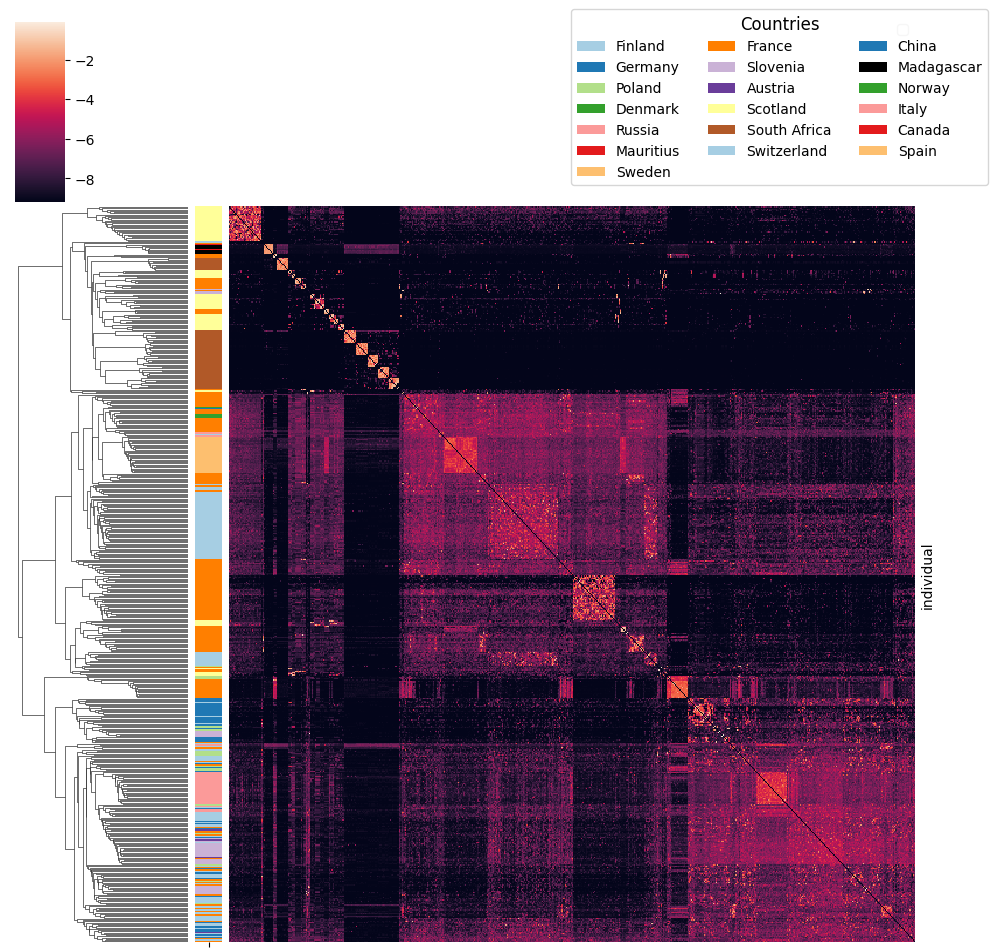

In [295]:


figsize = (10, 10)
dfg = df.groupby("individual").mean()
# Zscore normalise
for col in list(dfg):
    dfg[col] = np.log(dfg[col] + 0.0001)
row_linkage = scipy.cluster.hierarchy.linkage(dfg, method="average")
order = scipy.cluster.hierarchy.leaves_list(row_linkage)
x_pop = dfg.index.values[order]

cg = sns.clustermap(
    dfg[x_pop], row_linkage=row_linkage, col_cluster=False, # dfg[x_pop] dfgOrder[list(dfgOrder.individual)]
    figsize=figsize, rasterized=True, row_colors = pd.Series(get_ind_colours_lineages(dfCopy, country_colours)))


cg.ax_col_dendrogram.legend(ncol=5)
cg.ax_heatmap.set_yticks([])
cg.ax_heatmap.set_xticks([])




handles = [Patch(facecolor=country_colours[name]) for name in countries]
plt.legend(handles, country_colours, title='Countries',
           bbox_to_anchor=(1, 1), bbox_transform=plt.gcf().transFigure, loc='upper right',
           prop={'size': 10}, ncol=3, title_fontsize=12)

plt.show()


In [290]:
country_colours

{'Finland': (0.6509803921568628, 0.807843137254902, 0.8901960784313725),
 'Germany': (0.12156862745098039, 0.47058823529411764, 0.7058823529411765),
 'Poland': (0.6980392156862745, 0.8745098039215686, 0.5411764705882353),
 'Denmark': (0.2, 0.6274509803921569, 0.17254901960784313),
 'Russia': (0.984313725490196, 0.6039215686274509, 0.6),
 'Mauritius': (0.8901960784313725, 0.10196078431372549, 0.10980392156862745),
 'Sweden': (0.9921568627450981, 0.7490196078431373, 0.43529411764705883),
 'France': (1.0, 0.4980392156862745, 0.0),
 'Slovenia': (0.792156862745098, 0.6980392156862745, 0.8392156862745098),
 'Austria': (0.41568627450980394, 0.23921568627450981, 0.6039215686274509),
 'Scotland': (1.0, 1.0, 0.6),
 'South Africa': (0.6941176470588235, 0.34901960784313724, 0.1568627450980392),
 'Switzerland': (0.6509803921568628, 0.807843137254902, 0.8901960784313725),
 'China': (0.12156862745098039, 0.47058823529411764, 0.7058823529411765),
 'Madagascar': (0, 0, 0),
 'Norway': (0.2, 0.6274509803

In [237]:
pd.Series(get_ind_colours_subspecies(dfCopy))

KeyError: 'Iberiensis'

In [274]:
dfCopy["pop"]

0      C
1      C
2      C
3      C
4      C
      ..
583    M
584    M
585    M
586    O
587    M
Name: pop, Length: 588, dtype: object

In [189]:
df.head()

,0,1,2,3,4,5,6,7,8,9,...,1315,1316,1317,1318,1319,1320,1325,1326,1327,population
0,0.000000,0.005313,0.004247,0.001991,0.003205,0.005416,0.000660,0.000351,0.000821,0.000695,...,0.004918,0.006320,0.004043,0.006515,0.000596,0.000112,0.000241,0.001554,0.000441,C
1,0.002982,0.000000,0.002297,0.001136,0.001780,0.000452,0.000536,0.000183,0.000169,0.000355,...,0.006418,0.003066,0.004902,0.007969,0.000121,0.000041,0.000079,0.004442,0.000300,C
2,0.002884,0.001041,0.000000,0.011382,0.014053,0.000251,0.000624,0.001098,0.000169,0.000069,...,0.003588,0.002444,0.004313,0.001028,0.000117,0.000964,0.000342,0.010409,0.000904,C
3,0.000470,0.000263,0.008890,0.000000,0.077045,0.000101,0.000178,0.000080,0.000209,0.000066,...,0.000923,0.001910,0.000642,0.001964,0.000279,0.000081,0.000113,0.001858,0.000046,C
4,0.002678,0.002383,0.009646,0.074628,0.000000,0.000064,0.000027,0.000025,0.000317,0.000073,...,0.002399,0.000949,0.000344,0.001059,0.000044,0.000036,0.001763,0.114477,0.000025,C


In [187]:
remappedTs_meta.individual(remappedTs_meta.node(0).id)

Individual(id=0, flags=0, location=array([], dtype=float64), parents=array([], dtype=int32), nodes=array([], dtype=int32), metadata=b'')

In [134]:
import json
oldTree = tskit.load("/home/jobste/HBTS/OldTrees/Chr4.trees")

oldTree_nonH = oldTree.simplify(nonH)

In [135]:
subspecies = list(set([json.loads(t.metadata)['subpop'] for t in oldTree_nonH.populations()]))


sample_nodes = [oldTree_nonH.node(n) for n in oldTree_nonH.samples()]

samples_listed_by_subsp = [
    [s.id for s in sample_nodes if json.loads(oldTree_nonH.population(s.population).metadata)['subpop'] == pop]
    for pop in subspecies
]


In [136]:
A = oldTree_nonH.genealogical_nearest_neighbours(oldTree_nonH.samples(), samples_listed_by_subsp, num_threads=1)

In [137]:
A

array([[1.27291701e-03, 1.31184500e-03, 8.28393792e-01, ...,
        8.68380144e-02, 4.03355527e-02, 6.24187204e-04],
       [7.01957204e-04, 7.47454627e-04, 8.67791320e-01, ...,
        8.79685772e-02, 2.72766134e-02, 1.52915247e-04],
       [7.76997480e-04, 9.67335063e-04, 8.46109180e-01, ...,
        6.18268212e-02, 7.70412502e-02, 4.16474957e-04],
       ...,
       [1.30985735e-04, 6.06945312e-05, 9.90545064e-01, ...,
        3.60718121e-03, 4.59267865e-03, 4.44877511e-05],
       [1.43617412e-03, 1.19746024e-03, 8.45068832e-01, ...,
        6.89982901e-02, 5.39573749e-02, 5.70619805e-04],
       [1.49821035e-03, 1.77507032e-03, 4.48946415e-01, ...,
        4.13837656e-01, 2.90422579e-02, 1.06511398e-03]])